In [1]:
!pip install -q dcm2niix monai

In [2]:
import os, re, glob, shutil, subprocess, warnings
import numpy as np
import pandas as pd
import nibabel as nib
import torch
import monai.transforms as T
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm import tqdm

warnings.filterwarnings("ignore")
torch.set_num_threads(1)

OUT_DIR = "/kaggle/working/preprocessed"
TMP_DIR = "/tmp/nifti"
MAX_GB = 18

ORIENTATION = "LPS"
SPACING = (1.0, 1.0, 1.0)
SIZE = (192, 192, 192)
CT_WINDOW = (0, 900)

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(TMP_DIR, exist_ok=True)

candidates = glob.glob("/kaggle/input/*/train.csv") + glob.glob("/kaggle/input/*/*/train.csv")
BASE = next(os.path.dirname(p) for p in candidates
            if os.path.isdir(os.path.join(os.path.dirname(p), "series")))
SERIES_DIR = os.path.join(BASE, "series")

train = pd.read_csv(os.path.join(BASE, "train.csv"))
df = train[train["Modality"] == "CTA"].sort_values("SeriesInstanceUID").reset_index(drop=True)
print(len(df), "CTA")

1808 CTA


In [3]:
def base_transforms(hu_shift=0):
    return T.Compose([
        T.LoadImaged(keys="image", reader="NibabelReader"),
        T.EnsureChannelFirstd(keys="image"),
        T.ShiftIntensityd(keys="image", offset=hu_shift),
        T.Orientationd(keys="image", axcodes=ORIENTATION, labels=(("L", "R"), ("P", "A"), ("I", "S"))),
        T.CropForegroundd(keys="image", source_key="image"),
        T.Spacingd(keys="image", pixdim=SPACING, mode="bilinear"),
        T.ScaleIntensityRanged(keys="image", a_min=CT_WINDOW[0], a_max=CT_WINDOW[1],
                               b_min=-1.0, b_max=1.0, clip=True),
        T.EnsureTyped(keys="image"),
    ])


def crop_or_pad(volume, size=SIZE):
    out = np.full(size, volume.min(), dtype=np.float32)
    src, dst = [], []
    for axis, (n, s) in enumerate(zip(volume.shape, size)):
        length = min(n, s)
        src_start = n - length if axis == 2 else (n - length) // 2
        dst_start = (s - length) // 2
        src.append(slice(src_start, src_start + length))
        dst.append(slice(dst_start, dst_start + length))
    out[tuple(dst)] = volume[tuple(src)]
    return out


def pick_file(tmp):
    files = [f for f in os.listdir(tmp) if f.endswith(".nii")]
    if not files:
        return None, 0
    size = lambda f: os.path.getsize(os.path.join(tmp, f))
    corrected = lambda f: "_Eq_" in f or "_Tilt_" in f
    main = max([f for f in files if not corrected(f)] or files, key=size)
    stem = main[:-len(".nii")]
    versions = [f for f in files if re.fullmatch(re.escape(stem) + r"(_Tilt_\d+|_Eq_\d+|_Tilt_Eq_\d+)?\.nii", f)]
    return max(versions, key=lambda f: (corrected(f), size(f))), len(files)

In [4]:
def preprocess_series(uid):
    tmp = os.path.join(TMP_DIR, uid)
    os.makedirs(tmp, exist_ok=True)
    entry = {"uid": uid, "ok": False, "n_files": 0, "file": "", "p90": None, "hu_shift": 0, "shape": None, "message": ""}
    try:
        result = subprocess.run(["dcm2niix", "-z", "n", "-b", "n", "-f", uid, "-o", tmp, os.path.join(SERIES_DIR, uid)], capture_output=True, text=True)
        chosen, entry["n_files"] = pick_file(tmp)
        if chosen is None:
            entry["message"] = result.stdout[-300:]
            return entry
        entry["file"] = chosen[len(uid):-len(".nii")]
        path = os.path.join(tmp, chosen)

        entry["p90"] = round(float(np.percentile(np.asarray(nib.load(path).dataobj[::4, ::4, ::4]), 90)))
        entry["hu_shift"] = 1024 if entry["p90"] < -500 else 0

        data = base_transforms(entry["hu_shift"])({"image": path})
        volume = np.asarray(data["image"][0], dtype=np.float32)
        entry["shape"] = volume.shape
        np.save(os.path.join(OUT_DIR, f"{uid}.npy"), crop_or_pad(volume).astype(np.float16))
        entry["ok"] = True
    except Exception as e:
        entry["message"] = str(e)[:300]
    finally:
        shutil.rmtree(tmp, ignore_errors=True)
    return entry

In [5]:
def folder_size_gb(folder):
    total = 0
    for entry in os.scandir(folder):
        try:
            total += entry.stat().st_size
        except FileNotFoundError:
            pass
    return total / 1024**3


def run_chunk(start, end, workers=4):
    todo = [uid for uid in df["SeriesInstanceUID"].iloc[start:end]
            if not os.path.exists(os.path.join(OUT_DIR, f"{uid}.npy"))]
    log = []
    with ThreadPoolExecutor(max_workers=workers) as pool:
        futures = [pool.submit(preprocess_series, uid) for uid in todo]
        for future in tqdm(as_completed(futures), total=len(futures)):
            log.append(future.result())
            if folder_size_gb(OUT_DIR) > MAX_GB:
                print(f"[STOP] am atins {MAX_GB} GB")
                for f in futures:
                    f.cancel()
                break
    log = pd.DataFrame(log)
    log["modality"] = "CTA"
    log["label"] = log["uid"].map(df.set_index("SeriesInstanceUID")["Aneurysm Present"])
    log.to_csv(f"/kaggle/working/log_cta_{start}_{end}.csv", index=False)
    print("ok:", log["ok"].sum(), "/", len(log), "| hu_shift:", (log["hu_shift"] > 0).sum(),
          "| n_files > 2:", (log["n_files"] > 2).sum())
    return log


def check_outputs(n=3):
    files = sorted(os.listdir(OUT_DIR))[:n]
    fig, axes = plt.subplots(len(files), 3, figsize=(9, 3 * len(files)), squeeze=False)
    for row, f in zip(axes, files):
        v = np.load(os.path.join(OUT_DIR, f)).astype(np.float32)
        row[0].imshow(v[:, :, v.shape[2] // 2].T, cmap="gray")
        row[1].imshow(v[:, v.shape[1] // 2, :].T, cmap="gray", origin="lower")
        row[2].imshow(v[v.shape[0] // 2, :, :].T, cmap="gray", origin="lower")
    plt.tight_layout()
    plt.savefig("/kaggle/working/check_cta.png")
    plt.show()

  0%|          | 0/952 [00:00<?, ?it/s]nvImageCodec is not available; skipping pydicom decoder plugin registration.
nvImageCodec is not available; skipping pydicom decoder plugin registration.
  0%|          | 2/952 [00:08<1:00:00,  3.79s/it]nvImageCodec is not available; skipping pydicom decoder plugin registration.
nvImageCodec is not available; skipping pydicom decoder plugin registration.
nvImageCodec is not available; skipping pydicom decoder plugin registration.
  0%|          | 3/952 [00:13<1:02:52,  3.97s/it]nvImageCodec is not available; skipping pydicom decoder plugin registration.
nvImageCodec is not available; skipping pydicom decoder plugin registration.
  1%|          | 7/952 [00:25<48:35,  3.09s/it]nvImageCodec is not available; skipping pydicom decoder plugin registration.
nvImageCodec is not available; skipping pydicom decoder plugin registration.
  1%|          | 8/952 [00:29<52:30,  3.34s/it]nvImageCodec is not available; skipping pydicom decoder plugin registration.

ok: 949 / 952 | hu_shift: 399 | n_files > 2: 0


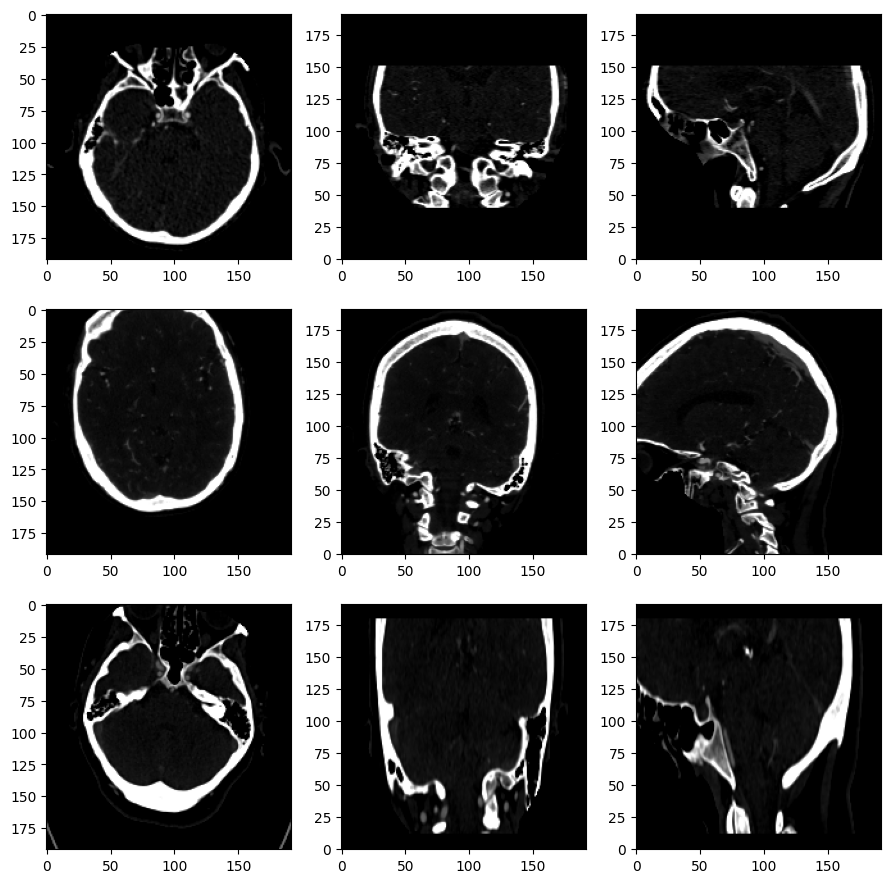

In [6]:
START, END = 0, 952

log = run_chunk(START, END)
check_outputs()

In [7]:
print(log[["file", "p90", "hu_shift", "shape"]])

      file  p90  hu_shift            shape
0            81         0  (191, 183, 111)
1    _Eq_1 -957      1024  (228, 236, 168)
2           104         0  (217, 203, 247)
3            62         0  (222, 215, 160)
4            57         0  (237, 219, 336)
..     ...  ...       ...              ...
947        -965      1024  (266, 262, 367)
948        -953      1024  (199, 210, 170)
949        -941      1024  (201, 200, 224)
950        -935      1024  (239, 239, 373)
951          95         0  (232, 227, 360)

[952 rows x 4 columns]
